# 01 - EDA and Label Construction
Tech-Triathlon 2026 Datathon - Waypoint Group

## 1. Setup and load

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42                      # fixed random seed so results repeat
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

D = "data/"
deliv   = pd.read_csv(D + "Training Data/deliveries_train.csv")
legs    = pd.read_csv(D + "Training Data/route_legs_train.csv")
t1_in   = pd.read_csv(D + "Test Data/task1_test_inputs.csv")
legs_te = pd.read_csv(D + "Test Data/route_legs_test.csv")
outlets = pd.read_csv(D + "General Data/outlets.csv")
veh     = pd.read_csv(D + "General Data/vehicles.csv")
cal     = pd.read_csv(D + "General Data/calendar.csv")
dtravel = pd.read_csv(D + "General Data/district_travel.csv")
allow   = pd.read_csv(D + "General Data/service_allowance.csv")
traffic = pd.read_csv(D + "General Data/traffic_speed.csv")
road    = pd.read_csv(D + "General Data/road_conditions.csv")

for name, df in [("deliveries_train", deliv), ("route_legs_train", legs),
                 ("task1_test_inputs", t1_in), ("route_legs_test", legs_te),
                 ("outlets", outlets), ("vehicles", veh), ("calendar", cal),
                 ("road_conditions", road), ("traffic_speed", traffic)]:
    print(f"{name:20s} {df.shape}")

deliveries_train     (92307, 20)
route_legs_train     (91894, 22)
task1_test_inputs    (5014, 20)
route_legs_test      (5014, 18)
outlets              (120, 9)
vehicles             (60, 9)
calendar             (910, 12)
road_conditions      (10920, 3)
traffic_speed        (576, 4)


## 2. Data overview and quality checks

In [2]:
print("Order dates:", deliv.order_date.min(), "to", deliv.order_date.max())
print("Test dates :", t1_in.order_date.min(), "to", t1_in.order_date.max())
print("\nDispatch status:"); print(deliv.dispatch_status.value_counts())
print("\nOrders per brand:"); print(deliv.brand.value_counts())
print("\nMissing values (train orders):"); print(deliv.isna().sum()[deliv.isna().sum() > 0])
print("\nMissing values (route legs):", int(legs.isna().sum().sum()))
print("Duplicate delivery_id:", deliv.delivery_id.duplicated().sum())

Order dates: 2024-01-01 to 2026-02-14
Test dates : 2026-02-16 to 2026-03-28

Dispatch status:
dispatch_status
attempted    90351
deferred      1543
not_run        413
Name: count, dtype: int64

Orders per brand:
brand
Fresh    87855
Style     2740
Tech      1712
Name: count, dtype: int64

Missing values (train orders):
dispatch_date           413
route_id                413
seq_in_route            413
vehicle_id              413
vehicle_type            413
vehicle_temp            413
planned_arrival_time    413
dtype: int64

Missing values (route legs): 0
Duplicate delivery_id: 0


The only blanks are the 413 `not_run` orders. They never left the depot, so they have no truck or route. That's expected, not dirty data. They are left out of Task 1 (no arrival to learn from) but kept for Task 2A (they are still demand).

## 3. Join each order to its route leg

In [3]:
def to_min(s):
    """'HH:MM' -> minutes after midnight"""
    p = s.str.split(":", expand=True).astype(int)
    return p[0] * 60 + p[1]

ran = deliv[deliv.route_id.notna()].copy()
ran["seq_in_route"] = ran.seq_in_route.astype(int)
df = ran.merge(legs, left_on=["route_id", "seq_in_route"],
               right_on=["route_id", "seq"], suffixes=("", "_leg"))
print("dispatched orders:", len(ran), "| matched legs:", len(df))
assert len(df) == len(ran)

time_cols = ["arrival_time", "leave_outlet_time", "window_open_time", "window_close_time",
             "planned_arrival_time", "planned_depart_time", "actual_depart_time"]
for c in time_cols:
    df[c + "_m"] = to_min(df[c])

# the leave time of one stop is the depart time of the next stop -> sanity check
df = df.sort_values(["route_id", "seq"])
nxt = df.groupby("route_id").actual_depart_time_m.shift(-1)
print("leave_outlet == next leg's depart:", round((nxt == df.leave_outlet_time_m)[nxt.notna()].mean() * 100, 1), "%")

dispatched orders: 91894 | matched legs: 91894


leave_outlet == next leg's depart: 100.0 %


## 4. Label construction (Task 1)
The booklet says: *a vehicle that arrives early waits until the window opens.* So handling starts at the **later** of arrival and window open:

- `service_min = leave_outlet_time - max(arrival_time, window_open_time)`
- `late = 1 if arrival_time > window_close_time else 0`

Below we test this. If waiting were counted as handling, early trucks would look much slower than normal ones.

early arrivals: 4.4 %
              naive_min  service_min
early                               
on time/late       15.0         15.0
early              30.0         13.0


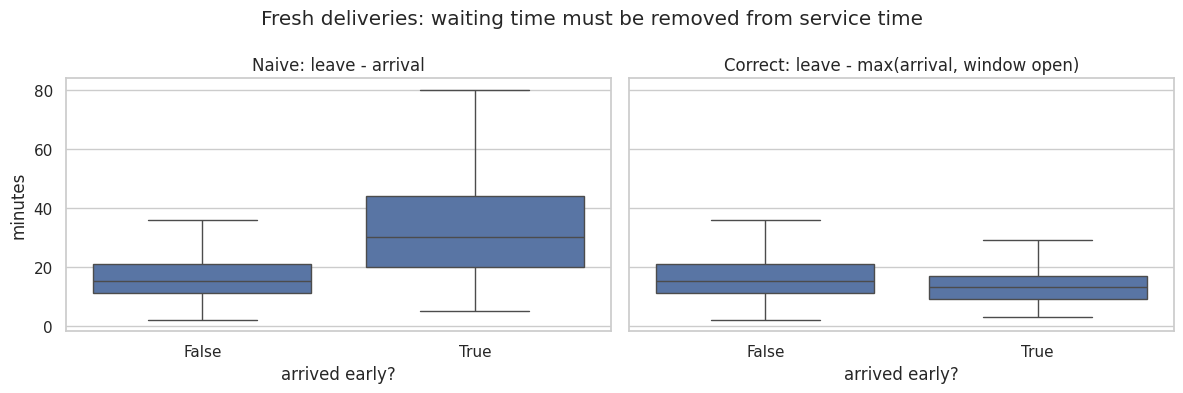

In [4]:
df["early"] = df.arrival_time_m < df.window_open_time_m
df["naive_min"] = df.leave_outlet_time_m - df.arrival_time_m
df["service_min"] = df.leave_outlet_time_m - np.maximum(df.arrival_time_m, df.window_open_time_m)
df["late"] = (df.arrival_time_m > df.window_close_time_m).astype(int)

print("early arrivals:", round(df.early.mean() * 100, 1), "%")
print(df.groupby("early")[["naive_min", "service_min"]].median().rename(index={False: "on time/late", True: "early"}))

fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for a, col, t in [(ax[0], "naive_min", "Naive: leave - arrival"),
                  (ax[1], "service_min", "Correct: leave - max(arrival, window open)")]:
    sns.boxplot(data=df[df.brand == "Fresh"], x="early", y=col, ax=a, showfliers=False)
    a.set_title(t); a.set_xlabel("arrived early?"); a.set_ylabel("minutes")
plt.suptitle("Fresh deliveries: waiting time must be removed from service time"); plt.tight_layout(); plt.show()

With the naive formula, early trucks look about twice as slow. After taking the waiting out, they match normal trucks. That supports the label rule.

In [5]:
print("Late rate overall:", round(df.late.mean() * 100, 1), "%")
print(df.groupby("brand").agg(orders=("late", "size"), late_rate=("late", "mean"),
                              service_median=("service_min", "median"),
                              service_mean=("service_min", "mean")).round(3))

Late rate overall: 19.6 %
       orders  late_rate  service_median  service_mean
brand                                                 
Fresh   87457      0.204            15.0        17.144
Style    2733      0.055            46.0        52.557
Tech     1704      0.025            52.0        60.585


## 5. EDA for Task 1 - what makes a delivery late?

### 5.1 Planned slack: how much time the plan leaves before the window closes

             mean   size
slack_bin               
(-999, 0]   0.983    653
(0, 15]     0.923   1743
(15, 30]    0.794   3078
(30, 60]    0.528  11146
(60, 120]   0.170  33946
(120, 999]  0.039  41328


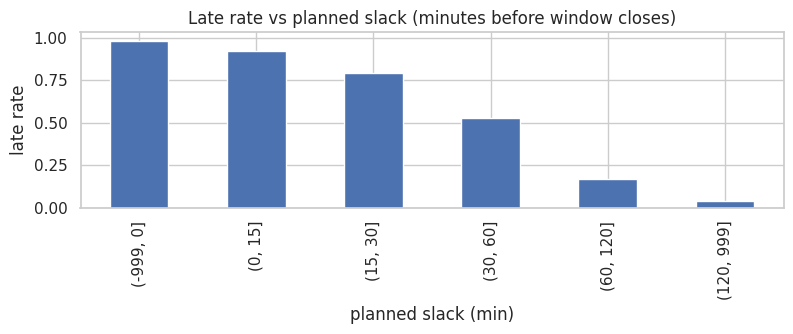

In [6]:
df["planned_slack"] = df.window_close_time_m - to_min(df.planned_arrival_time)
df["slack_bin"] = pd.cut(df.planned_slack, [-999, 0, 15, 30, 60, 120, 999])
s = df.groupby("slack_bin", observed=True).late.agg(["mean", "size"])
print(s.round(3))
s["mean"].plot(kind="bar", figsize=(8, 3.5), title="Late rate vs planned slack (minutes before window closes)")
plt.ylabel("late rate"); plt.xlabel("planned slack (min)"); plt.tight_layout(); plt.show()

### 5.2 Travel delay: actual vs planned travel, and what explains it

missing speed_index: 0 | missing disruption_index: 0
       travel_delay  depart_delay  travel_ratio
count      91894.00      91894.00      91894.00
mean          15.65         36.92          1.72
std           35.51         50.41          0.74
min         -119.00       -110.00          0.35
25%            3.00          7.00          1.24
50%            7.00         21.00          1.50
75%           15.00         49.00          2.00
max          895.00        897.00          9.33


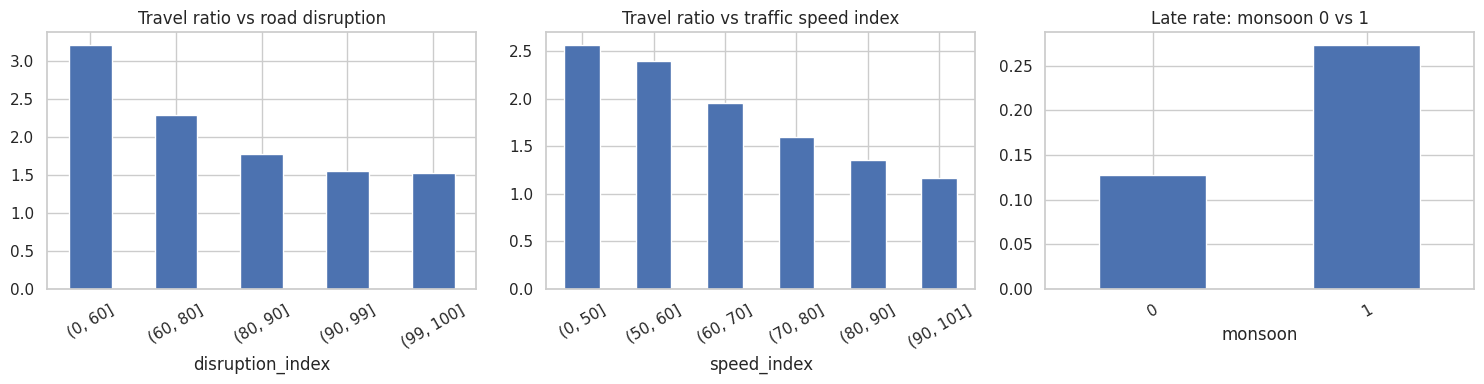

In [7]:
df["travel_delay"] = df.actual_travel_duration_min - df.planned_travel_duration_min
df["depart_delay"] = df.actual_depart_time_m - df.planned_depart_time_m
df["hour"] = df.planned_depart_time_m // 60
df = df.merge(traffic, left_on=["district", "hour", "monsoon"],
              right_on=["district", "hour", "monsoon"], how="left")
df = df.merge(road, left_on=["district", "date"], right_on=["district", "date"], how="left")
print("missing speed_index:", df.speed_index.isna().sum(), "| missing disruption_index:", df.disruption_index.isna().sum())
df["travel_ratio"] = df.actual_travel_duration_min / df.planned_travel_duration_min.clip(lower=1)
print(df[["travel_delay", "depart_delay", "travel_ratio"]].describe().round(2))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
df.groupby(pd.cut(df.disruption_index, [0, 60, 80, 90, 99, 100]), observed=True).travel_ratio.mean().plot(kind="bar", ax=ax[0], title="Travel ratio vs road disruption")
df.groupby(pd.cut(df.speed_index, [0, 50, 60, 70, 80, 90, 101]), observed=True).travel_ratio.mean().plot(kind="bar", ax=ax[1], title="Travel ratio vs traffic speed index")
df.groupby("monsoon").late.mean().plot(kind="bar", ax=ax[2], title="Late rate: monsoon 0 vs 1")
for a in ax: a.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

### 5.3 Late rate by district, stop position and day of week

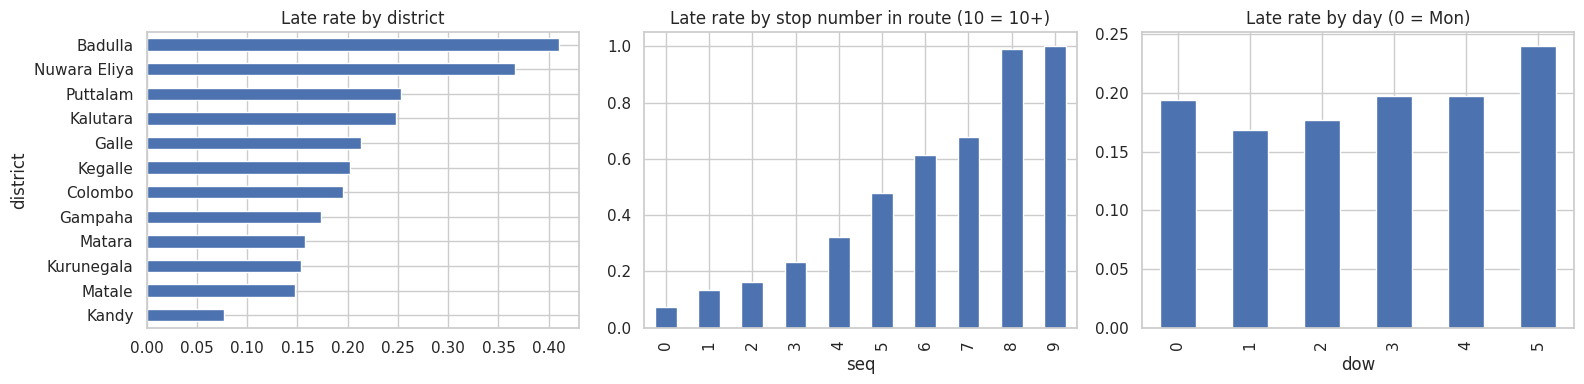

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
df.groupby("district").late.mean().sort_values().plot(kind="barh", ax=ax[0], title="Late rate by district")
df.groupby(df.seq.clip(upper=10)).late.mean().plot(kind="bar", ax=ax[1], title="Late rate by stop number in route (10 = 10+)")
df.groupby("dow").late.mean().plot(kind="bar", ax=ax[2], title="Late rate by day (0 = Mon)")
plt.tight_layout(); plt.show()

### 5.4 Calendar effects: payday, festival, holiday

In [9]:
cal_cols = ["date", "is_payday", "festival_ramp", "is_holiday", "is_weekend"]
df = df.merge(cal[cal_cols], on="date", how="left")
df["ramp_bin"] = pd.cut(df.festival_ramp, [-0.01, 0, 0.5, 1])
for c in ["is_payday", "ramp_bin", "is_holiday"]:
    print(df.groupby(c, observed=True)[["late", "service_min", "order_volume_m3"]].mean().round(3), "\n")

            late  service_min  order_volume_m3
is_payday                                     
0          0.193       18.600            2.062
1          0.235       24.107            2.253 

               late  service_min  order_volume_m3
ramp_bin                                         
(-0.01, 0.0]  0.183       17.247            2.010
(0.0, 0.5]    0.215       21.853            2.193
(0.5, 1.0]    0.290       31.767            2.546 

             late  service_min  order_volume_m3
is_holiday                                     
0           0.194       18.713            2.067
1           0.303       36.259            2.604 



## 6. EDA for Task 1 - what drives service time?

                 actual_median  actual_mean  allowance      n
brand dock_type                                              
Fresh rear_dock           15.0         16.9         15  60107
      street              14.0         17.6         16  27350
Style mall_bay            61.0         67.3         59    983
      rear_dock           30.0         34.7         38    652
      street              45.0         49.9         46   1098
Tech  mall_bay            74.0         87.8         55    284
      rear_dock           35.0         40.6         43    809
      street              67.0         74.4         55    611


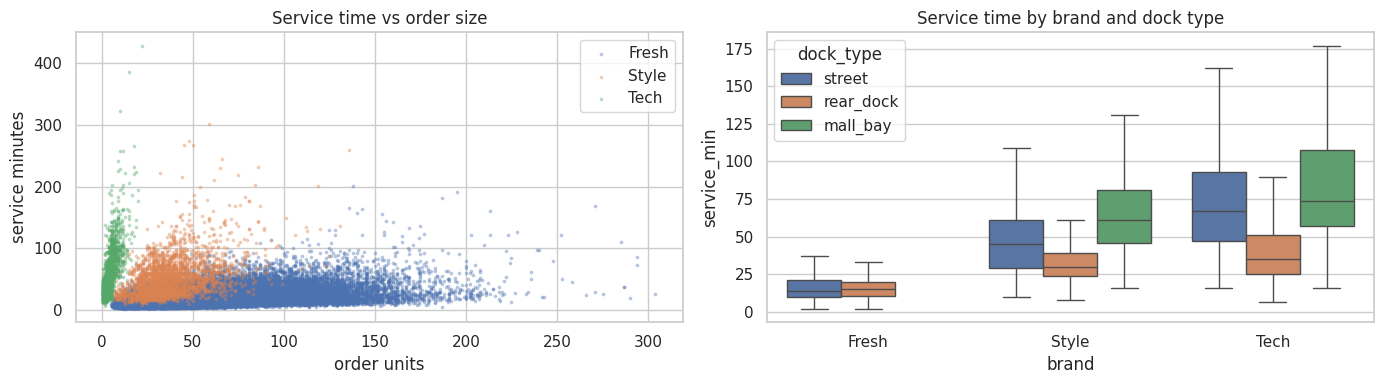

corr(service_min, order_units) by brand:
brand             
Fresh  service_min    0.51
Style  service_min    0.43
Tech   service_min    0.72
Name: order_units, dtype: float64


In [10]:
df = df.merge(outlets[["outlet_id", "dock_type", "parking_constraint"]], on="outlet_id", how="left")
df = df.merge(allow, on=["brand", "dock_type"], how="left")
print(df.groupby(["brand", "dock_type"]).agg(actual_median=("service_min", "median"),
      actual_mean=("service_min", "mean"), allowance=("service_allowance_min", "first"), n=("service_min", "size")).round(1))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for b, g in df.groupby("brand"):
    ax[0].scatter(g.order_units, g.service_min, s=3, alpha=0.3, label=b)
ax[0].set_xlabel("order units"); ax[0].set_ylabel("service minutes"); ax[0].legend(); ax[0].set_title("Service time vs order size")
sns.boxplot(data=df, x="brand", y="service_min", hue="dock_type", ax=ax[1], showfliers=False)
ax[1].set_title("Service time by brand and dock type")
plt.tight_layout(); plt.show()
print("corr(service_min, order_units) by brand:"); print(df.groupby("brand")[["service_min", "order_units"]].corr().iloc[0::2, 1].round(2))

### 6.1 Outliers

In [11]:
q = df.groupby("brand").service_min.quantile(0.99)
print("99th percentile per brand:"); print(q)
print("\nLongest 5 stops:")
print(df.nlargest(5, "service_min")[["delivery_id", "brand", "dock_type", "order_units", "order_volume_m3", "service_min"]])

99th percentile per brand:
brand
Fresh     54.00
Style    167.68
Tech     194.97
Name: service_min, dtype: float64

Longest 5 stops:
      delivery_id  brand dock_type  order_units  order_volume_m3  service_min
85739  ORD0086106   Tech  mall_bay           22           15.341          428
35627  ORD0035635   Tech  mall_bay           15           10.310          385
12314  ORD0012307   Tech  mall_bay           10            8.075          322
36325  ORD0036327  Style  mall_bay           59           13.088          301
16905  ORD0016854  Style  mall_bay           48           10.612          273


## 7. EDA for Task 2A - weekly demand

                  count   mean   std    min    25%    50%    75%     max
depot      brand                                                        
Kandy      Fresh  111.0  499.0  46.9  334.3  469.6  494.9  523.0   696.8
           Style  111.0   80.8  14.1   39.9   74.1   78.8   84.1   143.8
           Tech   111.0   21.3   8.7    2.8   15.0   20.3   25.8    47.8
Peliyagoda Fresh  111.0  954.1  85.9  623.5  895.9  945.9  994.4  1351.0
           Style  111.0  141.2  24.0   96.8  130.0  137.0  142.5   263.9
           Tech   111.0   29.8   9.0    7.9   23.2   29.7   36.4    56.5


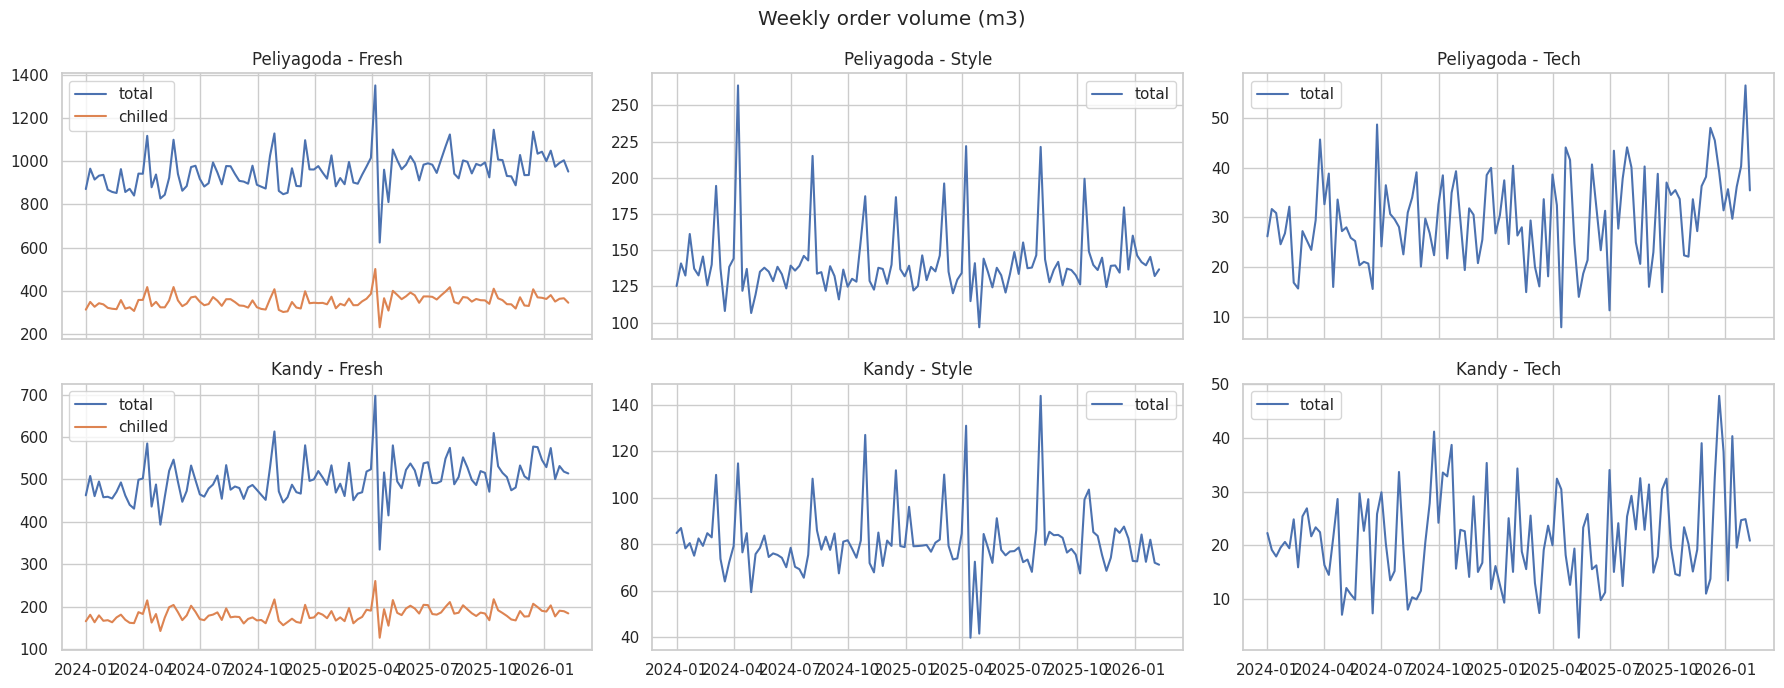

In [12]:
dem = deliv.merge(cal[["date", "iso_year", "iso_week"]], left_on="order_date", right_on="date", how="left")
dem["chilled_m3"] = np.where(dem.temp_requirement == "chilled", dem.order_volume_m3, 0)
wk = dem.groupby(["depot", "brand", "iso_year", "iso_week"]).agg(
        total_m3=("order_volume_m3", "sum"), chilled_m3=("chilled_m3", "sum"), orders=("delivery_id", "size")).reset_index()
wk["week_start"] = pd.to_datetime(wk.iso_year.astype(str) + "-W" + wk.iso_week.astype(str).str.zfill(2) + "-1", format="%G-W%V-%u")
print(wk.groupby(["depot", "brand"]).total_m3.describe().round(1))

fig, axes = plt.subplots(2, 3, figsize=(18, 7), sharex=True)
for i, dp in enumerate(["Peliyagoda", "Kandy"]):
    for j, br in enumerate(["Fresh", "Style", "Tech"]):
        g = wk[(wk.depot == dp) & (wk.brand == br)]
        axes[i, j].plot(g.week_start, g.total_m3, label="total")
        if br == "Fresh": axes[i, j].plot(g.week_start, g.chilled_m3, label="chilled")
        axes[i, j].set_title(f"{dp} - {br}"); axes[i, j].legend()
plt.suptitle("Weekly order volume (m3)"); plt.tight_layout(); plt.show()

In [13]:
t2a = pd.read_csv(D + "Test Data/task2a_test_inputs.csv")
print("Forecast weeks:", t2a[["iso_year", "iso_week"]].drop_duplicates().values.tolist())
last = wk.sort_values(["iso_year", "iso_week"]).iloc[-1]
print("Last training week:", [int(last.iso_year), int(last.iso_week)])
# weeks in task1 test inputs also count as history for Task 2A (booklet rule)
t1w = t1_in.merge(cal[["date", "iso_year", "iso_week"]], left_on="order_date", right_on="date")
print("Task 1 test inputs cover weeks:", t1w[["iso_year", "iso_week"]].drop_duplicates().values.tolist())

Forecast weeks: [[2026, 14], [2026, 15], [2026, 16], [2026, 17], [2026, 18], [2026, 19], [2026, 20], [2026, 21], [2026, 22], [2026, 23]]
Last training week: [2026, 7]
Task 1 test inputs cover weeks: [[2026, 8], [2026, 9], [2026, 10], [2026, 11], [2026, 12], [2026, 13]]


In [14]:
# festival effect on weekly volume
cw = cal.groupby(["iso_year", "iso_week"]).agg(ramp=("festival_ramp", "max"), paydays=("is_payday", "sum"),
                                              op_days=("is_operating", "sum")).reset_index()
wk2 = wk.merge(cw, on=["iso_year", "iso_week"])
f = wk2[wk2.brand == "Fresh"]
print(f.groupby(pd.cut(f.ramp, [-0.01, 0, 0.5, 1]), observed=True).total_m3.mean().round(1))
print(f.groupby("op_days").total_m3.mean().round(1))

ramp
(-0.01, 0.0]    708.8
(0.0, 0.5]      711.4
(0.5, 1.0]      780.9
Name: total_m3, dtype: float64
op_days
4    478.9
5    721.8
6    729.1
Name: total_m3, dtype: float64


## 8. Key findings

**Data quality**
- The data is clean: no duplicate IDs, and every dispatched order matches exactly one route leg. A stop's leave time equals the next leg's depart time 100% of the time.
- The only blanks are the 413 `not_run` orders, which is expected.

**Labels**
- 4.4% of trucks arrive early. With the naive formula their median time is 30 min; with waiting removed it's 13 min, the same as other trucks (15). That confirms `service = leave - max(arrival, window_open)`.
- 19.6% of deliveries are late. Fresh is 20.4%, Style 5.5% and Tech 2.5%.

**What drives lateness**
- **Planned slack is the strongest signal.** If the plan leaves 0-15 min before the window closes, over 90% arrive late. With 120+ min it's 4%.
- Trucks leave the depot a median of 21 min later than planned, and travel takes about 1.5x the planned time. Plans use free-flow speeds, which are too optimistic.
- Road disruption, traffic speed index and monsoon all slow travel down.
- Paydays (23.5% late vs 19.3%), festival build-up (29% at high ramp) and holidays (30%) raise both lateness and order size.

**What drives service time**
- Brand and dock type matter most. Fresh is about 15 min, while Style and Tech are 45-75 min.
- Order size matters: correlation with units is 0.51 for Fresh, 0.43 for Style and 0.72 for Tech.
- The dispatcher's allowance is close for Fresh but **badly underestimates Tech at mall bays and street docks** (actual about 74-88 min vs a 55 min allowance).
- Long tail: a few mall-bay Tech/Style stops take 4-7 hours. These look like real, rare events, so keep them but consider a robust loss (e.g. MAE or Huber) when modelling.

**Demand (Task 2A)**
- Peliyagoda Fresh is about 950 m3/week and Kandy Fresh about 500. Style and Tech are much smaller and noisier.
- Weeks with fewer operating days (holiday weeks) have lower volume, while festival build-up weeks go up about 10%.
- Forecast weeks are 2026 W14-W23. Task 1 test inputs cover W8-W13 and count as extra history.

## 9. Save the labelled training table

In [15]:
import os
os.makedirs("work", exist_ok=True)
df.to_csv("work/train_labelled.csv", index=False)
print("saved work/train_labelled.csv", df.shape)

saved work/train_labelled.csv (91894, 68)
